You need to run each pip install in a separate block for it to work (not sure why)

In [1]:
#pip install pyblp
#pip install pandas
#pip install pyRVtest
#pip install matplotlib
#pip install Jinja2

In [2]:
import pyblp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyRVtest
from IPython.display import display

import io
import re
from contextlib import redirect_stdout


pyblp.options.digits = 5
pyblp.options.verbose = False
pyblp.__version__

'1.1.2'

In [3]:
#choose the dataset you want
#product_data = pd.read_csv("LETF_product_month_level_v3.csv")
#product_data = pd.read_csv("LETF_product_month_level_v3_altSample.csv")
product_data = pd.read_csv("LETF_product_month_level_v4_patched.csv", low_memory=False)
#product_data = pd.read_csv("LETF_product_month_level_v4_altSample.csv")
#product_data = pd.read_csv("LETF_product_month_level_v6.csv")

# To drop missing values
# product_data.dropna(inplace=True)

# keep only bear or bull
product_data = product_data[product_data["market_m_bull_bear"] == "Bull"]

# need to create unique market id
product_data["market_ids"] = product_data.groupby(["month_t", "market_m_bull_bear"]).ngroup()+1

display(product_data[["month_t", "market_m_bull_bear", "market_ids"]].drop_duplicates().sort_values("market_ids").head())

# create some variable needed for estimation
product_data["log_product_fund_age"] = np.log(product_data["product_fund_age"])
product_data["product_tracking_err"] = abs(product_data["product_tracking_err"])
product_data["broad_specialized_ind"] = (product_data["broad_specialized"] ==  "broad-based").astype(int)

# drop NA
#product_data = product_data.dropna(subset=['Conduct_IV_sent_pls_resid'])
product_data = product_data.dropna(subset=['BLP_IV_hausman_mgmt_fee'])
#product_data = product_data[~((product_data["firm_f"].str.contains("Rydex", case=False, na=False)) & (product_data["product_L1_mtna"] < 10))]
#product_data = product_data[~((product_data["firm_f"].str.contains("ProFunds", case=False, na=False)) & (product_data["product_L1_mtna"] < 10))]

#product_data = product_data.loc[product_data['market_m_index'] != 'SML']

#display(product_data["Conduct_IV_sent_pls_resid"].describe())

# cluster SE
product_data['clustering_ids'] = product_data.market_ids

display(product_data["market_ids"].describe())


,month_t,market_m_bull_bear,market_ids
2807,2007.000000,Bull,1
2808,2007.083333,Bull,2
414,2007.166667,Bull,3
416,2007.250000,Bull,4
418,2007.333333,Bull,5


count    26935.000000
mean       118.424726
std         56.842606
min          1.000000
25%         71.000000
50%        120.000000
75%        167.000000
max        213.000000
Name: market_ids, dtype: float64

In [4]:
# need to rename to prices and shares  and IV for using built in package below
product_data = product_data.rename(columns={
    'product_exp_ratio': 'prices',
    'market_share_m_bull_bear': 'shares_old',
    'BLP_IV_hausman_exp_ratio': 'demand_instruments0',
    'BLP_IV_hausman_exp_ratio_x_broad': 'demand_instruments1',
    #'IV2_exp_ratio_vw': 'demand_instruments1', # This is not needed for logit which only requires one IV for the price
    'firm_f': 'firm_ids',
    'product_ticker': 'product_ids',
})

# need to recompute market share to make sure they sum up to 1 (PyBLP needs they sum up to less than 1!)
product_data["shares"] = (
    #product_data["product_mtna"] / product_data.groupby("market_ids")["product_mtna"].transform("sum")
    product_data["product_mtna"] / product_data["market_share_m_bull_bear_denom"]
)

product_data = product_data.loc[product_data['shares'] >= 0.0001]
product_data = product_data.loc[product_data['month_t'] >=2010]
product_data = product_data[product_data['firm_ids'].isin(['ProShares','Direxion','ProFunds'])]

#product_data['firm_ids'] = np.where(product_data['firm_ids']=='ProFunds', 'ProShares', product_data['firm_ids'])

# demand rotator and its instrument
product_data["rotator"] = (
    product_data["Conduct_IV_neg_vw_ind_resid_1m"] + product_data["Conduct_IV_neg_vw_ind_resid_2to5m"] + product_data["Conduct_IV_neg_vw_ind_resid_6to12m"]
)

'''
product_data["demand_instruments4"] = (
    product_data["demand_instruments0"] * product_data["rotator"]
)

product_data["demand_instruments5"] = (
    product_data["demand_instruments1"] * product_data["rotator"]
)

product_data["demand_instruments6"] = (
    product_data["demand_instruments2"] * product_data["rotator"]
)

product_data["demand_instruments7"] = (
    product_data["demand_instruments3"] * product_data["rotator"]
)
'''

display(product_data["prices"].describe())
display(product_data["shares_old"].describe())
display(product_data["shares"].describe())
display(product_data["product_mtna"].describe())
display(product_data["firm_ids"].describe())
display(product_data["product_ids"].describe())

display(product_data.info())
display(product_data.head(10))

count    15401.000000
mean         1.336491
std          0.566721
min          0.040000
25%          0.950000
50%          0.950000
75%          1.710000
max          2.920000
Name: prices, dtype: float64

count    15401.000000
mean         0.010806
std          0.026423
min          0.000100
25%          0.000517
50%          0.001608
75%          0.007283
max          0.303106
Name: shares_old, dtype: float64

count    15401.000000
mean         0.010806
std          0.026423
min          0.000100
25%          0.000517
50%          0.001608
75%          0.007283
max          0.303106
Name: shares, dtype: float64

count    15401.000000
mean       309.484920
std       1135.229874
min          1.000000
25%         11.300000
50%         34.600000
75%        163.300000
max      24666.600000
Name: product_mtna, dtype: float64

count        15401
unique           3
top       ProFunds
freq          5564
Name: firm_ids, dtype: object

count              15401
unique               146
top       UPRO US Equity
freq                 177
Name: product_ids, dtype: object

<class 'pandas.core.frame.DataFrame'>
Index: 15401 entries, 2 to 48274
Columns: 141 entries, market_m_index to rotator
dtypes: float64(116), int64(16), object(9)
memory usage: 16.7+ MB


None

,market_m_index,month_t,product_j,firm_ids,market_m_bull_bear,market_m_cluster,market_m_index_mret,product_fund_name,product_daily,product_leverage,...,csent_index,csent_index_resid,csent_index_resid1,chg_VIX,chg_VIX_resid,market_ids,broad_specialized_ind,clustering_ids,shares,rotator
2,AAPL,2023.166667,100446,Direxion,Bull,197,0.118650,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,62.0,62.493749,62.081951,-2.00,1.191402,195,0,195,0.000358,0.113479
5,AAPL,2023.250000,100446,Direxion,Bull,197,0.028988,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,63.7,63.783406,64.572340,-2.92,-2.140528,196,0,196,0.000392,0.063090
8,AAPL,2023.333333,100446,Direxion,Bull,197,0.046067,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,59.0,59.112726,57.809769,2.16,3.398498,197,0,197,0.000433,0.033786
11,AAPL,2023.416667,100446,Direxion,Bull,197,0.094328,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,64.2,64.537519,65.262418,-4.35,-1.797911,198,0,198,0.000554,0.038335
14,AAPL,2023.500000,100446,Direxion,Bull,197,0.012785,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,71.5,71.546324,71.394183,0.04,0.383423,199,0,199,0.000584,0.045185
17,AAPL,2023.583333,100446,Direxion,Bull,197,-0.042386,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,69.4,69.258574,69.763642,-0.06,-1.194157,200,0,200,0.000679,0.086289
20,AAPL,2023.666667,100446,Direxion,Bull,197,-0.088677,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,67.8,67.566024,66.932222,3.95,1.544927,201,0,201,0.000706,0.015871
23,AAPL,2023.750000,100446,Direxion,Bull,197,-0.002568,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,63.8,63.796481,63.669464,0.37,0.300578,202,0,202,0.000686,0.030278
26,AAPL,2023.833333,100446,Direxion,Bull,197,0.113743,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,61.3,61.381353,62.241691,-5.22,-2.183297,203,0,203,0.000566,0.067087
29,AAPL,2023.916667,100446,Direxion,Bull,197,0.013583,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,69.7,69.713961,69.761837,-0.47,-0.106840,204,0,204,0.000481,0.046672


In [5]:
# Compare share old (from CSV) and new (computed by me in python)
exact_match = (product_data["shares"] == product_data["shares_old"]).all()
close_match = np.allclose(product_data["shares"], product_data["shares_old"], rtol=1e-8, atol=1e-12)
abs_diff = (product_data["shares"] - product_data["shares_old"]).abs().max()

print("Exact equality:          ", exact_match)
print("All close (float-safe):  ", close_match)
print("Max absolute difference: ", abs_diff)

# Ad-hoc solution to make sure PyBLP run
#product_data["shares"] *= 0.5


Exact equality:           False
All close (float-safe):   True
Max absolute difference:  5.134781488891349e-16


In [6]:
# Prepare Logit with Demand Rotator
logit_formulation = pyblp.Formulation('prices + I(prices*broad_specialized_ind) + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')
logit_formulation


prices + I(prices * broad_specialized_ind) + product_tracking_err + product_past_1yr_ret + log_product_fund_age + Absorb[C(product_ids)] + Absorb[C(market_ids)]

In [7]:
# Show logit problem
logit_problem = pyblp.Problem(logit_formulation, product_data)
logit_problem

Dimensions:
 T     N     F    K1    MD    ED 
---  -----  ---  ----  ----  ----
177  15401   3    5     5     2  

Formulations:
     Column Indices:          0                  1                         2                     3                     4          
--------------------------  ------  ----------------------------  --------------------  --------------------  --------------------
X1: Linear Characteristics  prices  broad_specialized_ind*prices  product_tracking_err  product_past_1yr_ret  log_product_fund_age

In [8]:
# Solve logit
logit_results = logit_problem.solve(se_type='clustered')
logit_results

Problem Results Summary:
GMM    Objective   Clipped  Weighting Matrix  Covariance Matrix
Step     Value     Shares   Condition Number  Condition Number 
----  -----------  -------  ----------------  -----------------
 2    +2.4162E-27     0       +3.2748E+03        +1.6807E+02   

Cumulative Statistics:
Computation   Objective 
   Time      Evaluations
-----------  -----------
 00:00:00         2     

Beta Estimates (Robust SEs Adjusted for 177 Clusters in Parentheses):
   prices      broad_specialized_ind*prices  product_tracking_err  product_past_1yr_ret  log_product_fund_age
-------------  ----------------------------  --------------------  --------------------  --------------------
 -3.7372E+00           +1.7883E-01               -1.3830E+00           +2.5445E-01           +7.0542E-01     
(+3.4929E-01)         (+3.7651E-01)             (+2.5213E-01)         (+3.5876E-02)         (+4.0228E-02)    

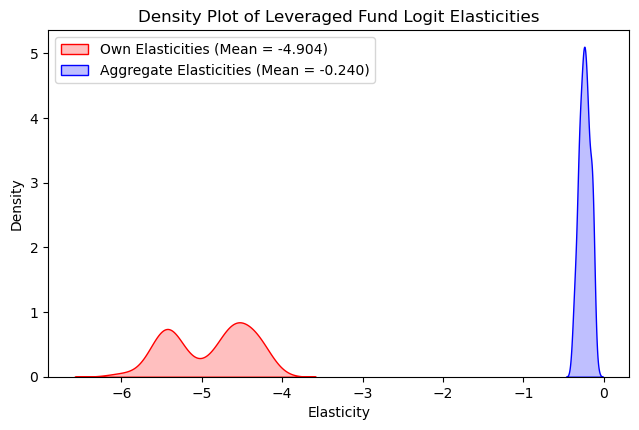

In [9]:
# compute elasticities, diversion ratio
logit_elasticities = logit_results.compute_elasticities()
logit_diversions = logit_results.compute_diversion_ratios()
logit_means = logit_results.extract_diagonal_means(logit_elasticities)
logit_aggregates = logit_results.compute_aggregate_elasticities(factor=0.1)

mean_own = logit_means.flatten().mean()
mean_agg = logit_aggregates.flatten().mean()

import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size if needed
plt.figure(figsize=(10*0.75, 6*0.75))

# Plot the density (KDE)
sns.kdeplot(logit_means.flatten(), color='red', fill=True, label=f"Own Elasticities (Mean = {mean_own:.3f})")
sns.kdeplot(logit_aggregates.flatten(), color='blue', fill=True, label=f"Aggregate Elasticities (Mean = {mean_agg:.3f})")

# Formatting
plt.legend()
plt.xlabel("Elasticity")
plt.ylabel("Density")
plt.title("Density Plot of Leveraged Fund Logit Elasticities")

# Save and show
plt.savefig("./logit_lasticities_density_LETF.pdf", format="pdf", bbox_inches="tight")
plt.show()


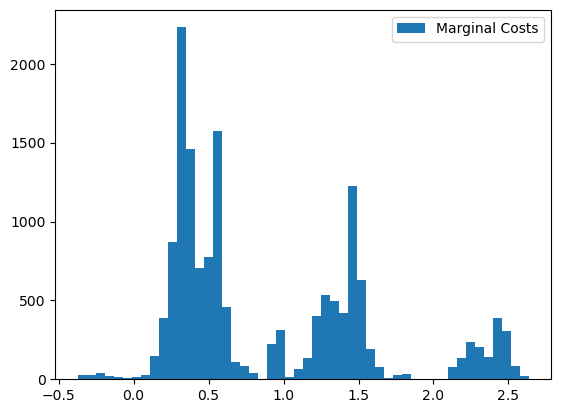

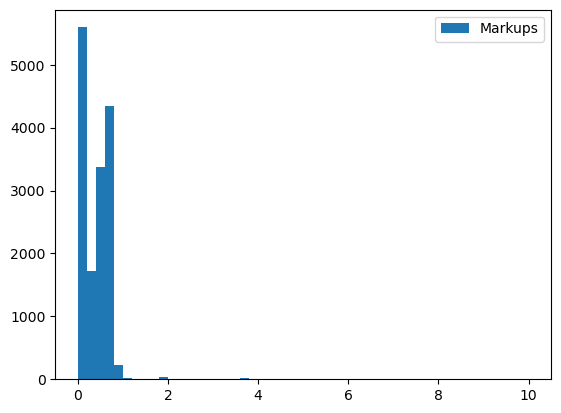

array([[0.5131444 ],
       [0.51917807],
       [0.51453082],
       ...,
       [0.39231832],
       [0.39808563],
       [0.40859748]], shape=(15401, 1))

array([[0.459848  ],
       [0.45349677],
       [0.45838862],
       ...,
       [0.52156302],
       [0.51452972],
       [0.5017104 ]], shape=(15401, 1))

count    15401.000000
mean         0.898159
std          0.676336
min         -0.372571
25%          0.350171
50%          0.559391
75%          1.426860
max          2.634906
dtype: float64

count    15401.000000
mean         0.427641
std          0.424962
min          0.096529
25%          0.168577
50%          0.414309
75%          0.630576
max         10.314270
dtype: float64

In [10]:
# compute costs and markups

costs = logit_results.compute_costs()
plt.hist(costs, bins=50);
plt.legend(["Marginal Costs"]);
plt.savefig("./logit_marginalcost_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

markups = logit_results.compute_markups(costs=costs)
plt.hist(markups, bins=50, range=(0,10));
plt.legend(["Markups"]);
plt.savefig("./logit_markups_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

display(costs)
display(markups)

display(pd.Series(costs.ravel()).describe())
display(pd.Series(markups.ravel()).describe())


In [11]:
# For BLP we need more instruments
#  19  BLP_IV_implied_swap_rate                            26937 non-null  float64
#  20  BLP_IV_implied_fund_swap_rate                       26704 non-null  float64
#  21  BLP_IV_delta_vix                                    26937 non-null  float64
#  22  BLP_IV_ICR                                          26553 non-null  float64
#  23  BLP_IV_ICR_ret                                      26937 non-null  float64
#  24  BLP_IV_hausman_exp_ratio                            26937 non-null  float64
#  25  BLP_IV_hausman_op_cost                              26937 non-null  float64
#  26  BLP_IV_hausman_mgmt_fee                             26937 non-null  float64
#  27  BLP_IV_waldfan_exp_ratio                            26937 non-null  float64
#  28  BLP_IV_waldfan_op_cost                              26937 non-null  float64
#  29  BLP_IV_waldfan_mgmt_fee                             26937 non-null  float64
#  30  BLP_IV_rival_funds1                                 26937 non-null  int64  
#  31  BLP_IV_rival_funds2                                 26937 non-null  int64  
#  32  BLP_IV_rival_funds3                                 26937 non-null  int64  
#  33  BLP_IV_rival_funds4                                 26937 non-null  int64  
#  34  BLP_IV_rival_funds5                                 26937 non-null  int64  
#  35  BLP_IV_rival_funds6                                 26937 non-null  int64  
#  36  BLP_IV_newproduct_1                                 26937 non-null  int64  
#  37  BLP_IV_newp_exp_ratio_1                             26937 non-null  float64
#  38  BLP_IV_newp_op_cost_1                               26937 non-null  float64
#  39  BLP_IV_newp_mgmt_fee_1                              26937 non-null  float64
#  40  BLP_IV_newproduct_2                                 26937 non-null  int64  
#  41  BLP_IV_newp_exp_ratio_2                             26937 non-null  float64
#  42  BLP_IV_newp_op_cost_2                               26937 non-null  float64
#  43  BLP_IV_newp_mgmt_fee_2                              2035 non-null   float64
#  44  BLP_IV_newproduct_3                                 26937 non-null  int64  
#  45  BLP_IV_newp_exp_ratio_3                             26937 non-null  float64
#  46  BLP_IV_newp_op_cost_3                               26937 non-null  float64
#  47  BLP_IV_newp_mgmt_fee_3                              1447 non-null   float64

product_data["BLP_IV_rival_funds1_x_broad"] = (
    product_data["BLP_IV_rival_funds1"] * product_data["broad_specialized_ind"]
)

product_data = product_data.rename(columns={
    # This is too correlated with BLP_IV_hausman_exp_ratio (renamed as demand_instruments1 above for logit estimation)
    #'BLP_IV_hausman_op_cost': 'demand_instruments1',
    # This one seems to work since it has some nice independent variation
    'BLP_IV_rival_funds1': 'demand_instruments2'
    # This 
    #'BLP_IV_rival_funds4': 'demand_instruments2'
})

# Prepare BLP 
X1_formulation = pyblp.Formulation('0 + prices + I(prices*broad_specialized_ind) + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')  
X2_formulation = pyblp.Formulation('0 + prices')
product_formulations = (X1_formulation, X2_formulation)
product_formulations

(prices + I(prices * broad_specialized_ind) + product_tracking_err + product_past_1yr_ret + log_product_fund_age + Absorb[C(product_ids)] + Absorb[C(market_ids)],
 prices)

In [12]:
mc_integration = pyblp.Integration('monte_carlo', size=3000, specification_options={'seed': 623543})
mc_integration

Configured to construct nodes and weights with Monte Carlo simulation with options {seed: 623543}.

In [13]:
mc_problem = pyblp.Problem(product_formulations, product_data, integration=mc_integration)
mc_problem

Dimensions:
 T     N     F     I      K1    K2    MD    ED 
---  -----  ---  ------  ----  ----  ----  ----
177  15401   3   531000   5     1     6     2  

Formulations:
       Column Indices:           0                  1                         2                     3                     4          
-----------------------------  ------  ----------------------------  --------------------  --------------------  --------------------
 X1: Linear Characteristics    prices  broad_specialized_ind*prices  product_tracking_err  product_past_1yr_ret  log_product_fund_age
X2: Nonlinear Characteristics  prices                                                                                                

In [14]:
bfgs = pyblp.Optimization('bfgs', {'gtol': 1e-7})
bfgs

Configured to optimize using the BFGS algorithm implemented in SciPy with analytic gradients and options {gtol: +1.0000E-07}.

In [15]:
# Solve BLP
results = mc_problem.solve(np.identity(1), optimization=bfgs)
results

Problem Results Summary:
GMM    Objective    Gradient                 Clipped  Weighting Matrix  Covariance Matrix
Step     Value        Norm        Hessian    Shares   Condition Number  Condition Number 
----  -----------  -----------  -----------  -------  ----------------  -----------------
 2    +4.2986E+00  +9.9018E-13  +1.9250E+00     0       +8.4925E+04        +4.9930E+17   

Cumulative Statistics:
Computation  Optimizer  Optimization   Objective   Fixed Point  Contraction
   Time      Converged   Iterations   Evaluations  Iterations   Evaluations
-----------  ---------  ------------  -----------  -----------  -----------
 00:20:00       Yes          9            28          54330       166653   

Nonlinear Coefficient Estimates (Robust SEs in Parentheses):
Sigma:     prices    
------  -------------
prices   +2.2465E+00 
        (+1.3027E-01)

Beta Estimates (Robust SEs in Parentheses):
   prices      broad_specialized_ind*prices  product_tracking_err  product_past_1yr_ret  log

In [16]:
# compute elasticities, diversion ratio, costs, and markups
elasticities = results.compute_elasticities()
diversions = results.compute_diversion_ratios()
costs = results.compute_costs()
markups = results.compute_markups(costs=costs)

In [17]:
means = results.extract_diagonal_means(elasticities)
aggregates = results.compute_aggregate_elasticities(factor=0.1)

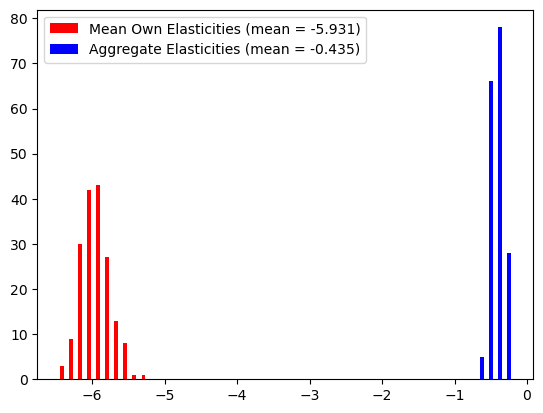

In [18]:
mean_own = means.flatten().mean()
mean_agg = aggregates.flatten().mean()

plt.hist(
    [means.flatten(), aggregates.flatten()], 
    color=['red', 'blue'], 
    bins=50
);
# --- legend with numbers embedded ---
plt.legend([
    f"Mean Own Elasticities (mean = {mean_own:.3f})",
    f"Aggregate Elasticities (mean = {mean_agg:.3f})"
])
plt.savefig("./elasticities_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

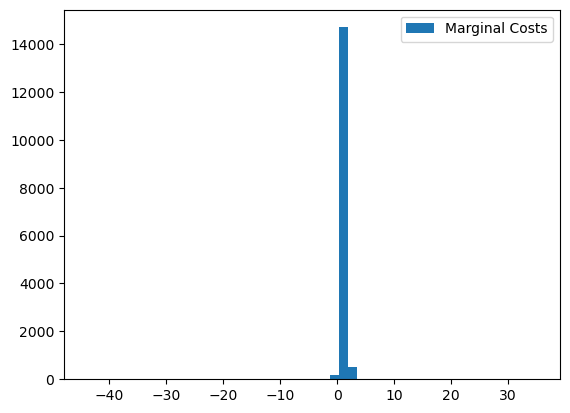

In [19]:
costs = results.compute_costs()
plt.hist(costs, bins=50);
plt.legend(["Marginal Costs"]);
plt.savefig("./marginalcost_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

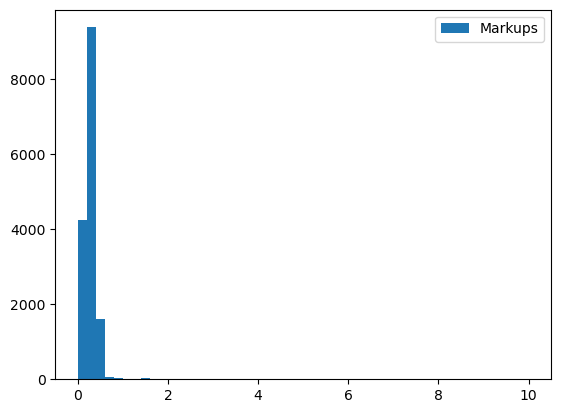

In [20]:
markups = results.compute_markups(costs=costs)
plt.hist(markups, bins=50, range=(0,10));
plt.legend(["Markups"]);
plt.savefig("./markups_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

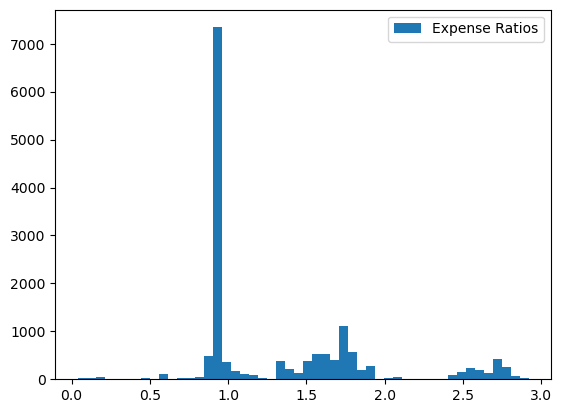

In [21]:
prices = product_data["prices"]
plt.hist(prices, bins=50);
plt.legend(["Expense Ratios"]);
plt.savefig("./expenseratio_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [22]:
# 0. Extract beta estimates from PyBLP results
beta = results.beta.flatten()
beta_se = results.beta_se.flatten()
beta_names = list(results.beta_labels)

beta_df = pd.DataFrame({
    "Variable": beta_names, "Coef": beta, "SE": beta_se
})

display(beta_df)


,Variable,Coef,SE
0,prices,-6.780187,0.077023
1,broad_specialized_ind*prices,0.512112,0.313115
2,product_tracking_err,-1.579048,0.240304
3,product_past_1yr_ret,0.261554,0.028652
4,log_product_fund_age,0.785366,0.032465


In [23]:
# For BLP with more RCs, we need more instruments
#  19  BLP_IV_implied_swap_rate                            26937 non-null  float64
#  20  BLP_IV_implied_fund_swap_rate                       26704 non-null  float64
#  21  BLP_IV_delta_vix                                    26937 non-null  float64
#  22  BLP_IV_ICR                                          26553 non-null  float64
#  23  BLP_IV_ICR_ret                                      26937 non-null  float64
#  24  BLP_IV_hausman_exp_ratio                            26937 non-null  float64
#  25  BLP_IV_hausman_op_cost                              26937 non-null  float64
#  26  BLP_IV_hausman_mgmt_fee                             26937 non-null  float64
#  27  BLP_IV_waldfan_exp_ratio                            26937 non-null  float64
#  28  BLP_IV_waldfan_op_cost                              26937 non-null  float64
#  29  BLP_IV_waldfan_mgmt_fee                             26937 non-null  float64
#  30  BLP_IV_rival_funds1                                 26937 non-null  int64  
#  31  BLP_IV_rival_funds2                                 26937 non-null  int64  
#  32  BLP_IV_rival_funds3                                 26937 non-null  int64  
#  33  BLP_IV_rival_funds4                                 26937 non-null  int64  
#  34  BLP_IV_rival_funds5                                 26937 non-null  int64  
#  35  BLP_IV_rival_funds6                                 26937 non-null  int64  
#  36  BLP_IV_newproduct_1                                 26937 non-null  int64  
#  37  BLP_IV_newp_exp_ratio_1                             26937 non-null  float64
#  38  BLP_IV_newp_op_cost_1                               26937 non-null  float64
#  39  BLP_IV_newp_mgmt_fee_1                              26937 non-null  float64
#  40  BLP_IV_newproduct_2                                 26937 non-null  int64  
#  41  BLP_IV_newp_exp_ratio_2                             26937 non-null  float64
#  42  BLP_IV_newp_op_cost_2                               26937 non-null  float64
#  43  BLP_IV_newp_mgmt_fee_2                              2035 non-null   float64
#  44  BLP_IV_newproduct_3                                 26937 non-null  int64  
#  45  BLP_IV_newp_exp_ratio_3                             26937 non-null  float64
#  46  BLP_IV_newp_op_cost_3                               26937 non-null  float64
#  47  BLP_IV_newp_mgmt_fee_3                              1447 non-null   float64

product_data = product_data.rename(columns={
    'BLP_IV_rival_funds4': 'demand_instruments3'
})

In [24]:
product_data = product_data.rename(columns={
    'BLP_IV_newproduct_1': 'demand_instruments4'
})

# Prepare BLP with additional RCs V2
X1_formulation = pyblp.Formulation('0 + prices + I(prices*broad_specialized_ind) + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')  
X2_formulation = pyblp.Formulation('0 + prices + log_product_fund_age + product_past_1yr_ret')
product_formulations = (X1_formulation, X2_formulation)
product_formulations

mc_integration = pyblp.Integration('monte_carlo', size=3000, specification_options={'seed': 623543})
mc_integration

mc_problem = pyblp.Problem(product_formulations, product_data, integration=mc_integration)
mc_problem

bfgs = pyblp.Optimization('bfgs', {'gtol': 1e-7})
bfgs

# Solve BLP
results_v3 = mc_problem.solve(np.identity(3), optimization=bfgs)
results_v3

Problem Results Summary:
GMM    Objective    Gradient        Hessian         Hessian     Clipped  Weighting Matrix  Covariance Matrix
Step     Value        Norm      Min Eigenvalue  Max Eigenvalue  Shares   Condition Number  Condition Number 
----  -----------  -----------  --------------  --------------  -------  ----------------  -----------------
 2    +8.8284E+01  +5.1605E-06   +2.6023E+01     +8.4329E+01       0       +1.3590E+05        +2.3701E+17   

Cumulative Statistics:
Computation  Optimizer  Optimization   Objective   Fixed Point  Contraction
   Time      Converged   Iterations   Evaluations  Iterations   Evaluations
-----------  ---------  ------------  -----------  -----------  -----------
 01:45:30       No           23           126        297580       913756   

Nonlinear Coefficient Estimates (Robust SEs in Parentheses):
       Sigma:            prices      log_product_fund_age  product_past_1yr_ret
--------------------  -------------  --------------------  ----------

In [25]:
# compute elasticities, diversion ratio, costs, and markups for RC v3
elasticities = results_v3.compute_elasticities()
diversions = results_v3.compute_diversion_ratios()
costs = results_v3.compute_costs()
markups = results_v3.compute_markups(costs=costs)

means = results_v3.extract_diagonal_means(elasticities)
aggregates = results_v3.compute_aggregate_elasticities(factor=0.1)

mean_own = means.flatten().mean()
mean_agg = aggregates.flatten().mean()
mean_own

np.float64(-6.024110458612538)

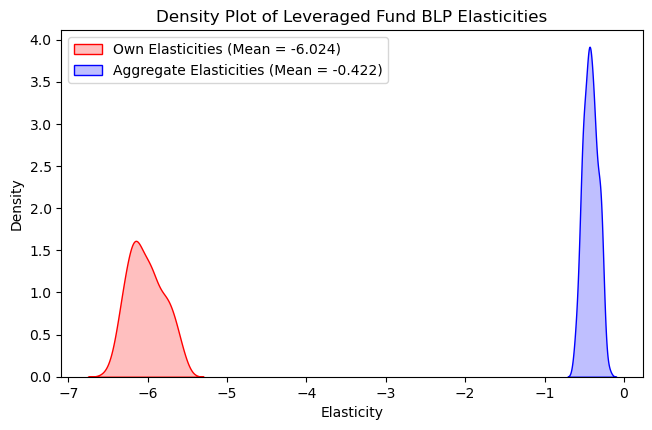

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep your mean calculations
mean_own = means.flatten().mean()
mean_agg = aggregates.flatten().mean()

# Set the figure size if needed
plt.figure(figsize=(10*0.75, 6*0.75))

# Plot the density (KDE)
sns.kdeplot(means.flatten(), color='red', fill=True, label=f"Own Elasticities (Mean = {mean_own:.3f})")
sns.kdeplot(aggregates.flatten(), color='blue', fill=True, label=f"Aggregate Elasticities (Mean = {mean_agg:.3f})")

# Formatting
plt.legend()
plt.xlabel("Elasticity")
plt.ylabel("Density")
plt.title("Density Plot of Leveraged Fund BLP Elasticities")

# Save and show
plt.savefig("./BLP_elasticities_density_LETF.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [27]:
# compute elasticities, diversion ratio
results_v3.compute_elasticities()

array([[-5.76260851e+00,  2.47925431e-03,  9.92077003e-02, ...,
                    nan,             nan,             nan],
       [-5.70761786e+00,  2.46190025e-03,  7.93751008e-02, ...,
                    nan,             nan,             nan],
       [-5.74842231e+00,  3.18523471e-03,  7.24247975e-02, ...,
                    nan,             nan,             nan],
       ...,
       [ 1.32534354e-01,  1.97992090e-03,  3.63509502e-03, ...,
                    nan,             nan,             nan],
       [ 1.42446465e-01,  2.54111393e-03,  3.40408541e-03, ...,
                    nan,             nan,             nan],
       [ 1.35553812e-01,  1.65603068e-03,  3.52036976e-03, ...,
                    nan,             nan,             nan]],
      shape=(15401, 101))

In [28]:
import os
import pandas as pd
import numpy as np

# suppose your data frame is called df
# and it contains a column named 'market_id'
market_ids = product_data['market_ids'].dropna().unique()

# optional: sort them
market_ids = sorted(market_ids)

# folder to save outputs
output_dir = "elasticity_outputs_broad"
os.makedirs(output_dir, exist_ok=True)

for mid in market_ids:
    try:
        # compute elasticities for this market
        elast = logit_results.compute_elasticities(market_id=mid)

        # convert to DataFrame
        elast_df = pd.DataFrame(elast)

        # save to csv
        out_file = os.path.join(output_dir, f"logit_elasticities_lev_market_{mid}.csv")
        elast_df.to_csv(out_file, index=False)

        print(f"Saved: {out_file}")

    except Exception as e:
        print(f"Error for market_id={mid}: {e}")

Saved: elasticity_outputs_broad\logit_elasticities_lev_market_37.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_38.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_39.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_40.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_41.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_42.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_43.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_44.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_45.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_46.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_47.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_48.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_49.csv
Saved: elasticity_outputs_broad\logit_elasticities_lev_market_50.csv
Saved: elasticity_outputs_broad\lo

In [29]:
import os
import pandas as pd
import numpy as np

# suppose your data frame is called df
# and it contains a column named 'market_id'
market_ids = product_data['market_ids'].dropna().unique()

# optional: sort them
market_ids = sorted(market_ids)

# folder to save outputs
output_dir = "elasticity_outputs_broad"
os.makedirs(output_dir, exist_ok=True)

for mid in market_ids:
    try:
        # compute elasticities for this market
        elast = results_v3.compute_elasticities(market_id=mid)

        # convert to DataFrame
        elast_df = pd.DataFrame(elast)

        # save to csv
        out_file = os.path.join(output_dir, f"elasticities_lev_market_{mid}.csv")
        elast_df.to_csv(out_file, index=False)

        print(f"Saved: {out_file}")

    except Exception as e:
        print(f"Error for market_id={mid}: {e}")

Saved: elasticity_outputs_broad\elasticities_lev_market_37.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_38.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_39.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_40.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_41.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_42.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_43.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_44.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_45.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_46.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_47.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_48.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_49.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_50.csv
Saved: elasticity_outputs_broad\elasticities_lev_market_51.csv
Saved: elasticity_outputs_broad\elasticities_lev_market

In [30]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.25 if {f, g} == {"ProShares", "Direxion"}
        else 0.25 if {f, g} == {"ProFunds", "Direxion"}
       else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.5 if {f, g} == {"ProShares", "Direxion"}
        else 0.5 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.55 if {f, g} == {"ProShares", "Direxion"}
        else 0.55 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.6 if {f, g} == {"ProShares", "Direxion"}
        else 0.6 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.65 if {f, g} == {"ProShares", "Direxion"}
        else 0.65 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.7 if {f, g} == {"ProShares", "Direxion"}
        else 0.7 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.75 if {f, g} == {"ProShares", "Direxion"}
        else 0.75 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.040)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

Dimensions:
 T     N     M    L   d_z0
---  -----  ---  ---  ----
177  15401  11    1    3  

Formulations:
Column Indices:            0                         1                                       2                        
----------------  --------------------  ----------------------------  ------------------------------------------------
w: Marginal Cost  log_product_fund_age      product_tracking_err                    product_past_1yr_ret              
z0: Instruments   BLP_IV_rival_funds2   Conduct_IV_csent_index_resid  BLP_IV_rival_funds2*Conduct_IV_csent_index_resid

Models:
                                0              1         2         3         4         5         6         7         8         9         10   
---------------------  -------------------  --------  --------  --------  --------  --------  --------  --------  --------  --------  --------
 Model - Downstream    perfect_competition  bertrand  bertrand  bertrand  bertrand  bertrand  bertrand  bertrand  bertran

In [31]:
testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

Computing Markups ... 
Total Time is ... 65.47245717048645




Testing Results - Instruments z0:
  TRV:                                                                                 |   F-stats:                                                                                                  |    MCS:                
--------  ---  -----  -----  -----  -----  -----  -----  -----  -----  ------  ------  |  ----------  ---  -------  -------  -------  -------  -------  -------  -------  -------  -------  -------  |  --------  ------------
 models    0     1      2      3      4      5      6      7      8      9       10    |    models     0      1        2        3        4        5        6        7        8        9       10     |   models   MCS p-values
--------  ---  -----  -----  -----  -----  -----  -----  -----  -----  ------  ------  |  ----------  ---  -------  -------  -------  -------  -------  -------  -------  -------  -------  -------  |  --------  ------------
   0      nan  2.291  2.073  1.908  1.872  1.832  1.784  1.723  1.641  0

In [32]:
# Save the level markup, level marginal cost, and lerner index data into the df
product_data['BLP_mu_pc'] = testing_results.markups[0]
product_data['BLP_mu_bt'] = testing_results.markups[1]
product_data['BLP_mu_bt_prosh_direx_025'] = testing_results.markups[2]
product_data['BLP_mu_bt_prosh_direx_050'] = testing_results.markups[3]
product_data['BLP_mu_bt_prosh_direx_055'] = testing_results.markups[4]
product_data['BLP_mu_bt_prosh_direx_060'] = testing_results.markups[5]
product_data['BLP_mu_bt_prosh_direx_065'] = testing_results.markups[6]
product_data['BLP_mu_bt_prosh_direx_070'] = testing_results.markups[7]
product_data['BLP_mu_bt_prosh_direx_075'] = testing_results.markups[8]
product_data['BLP_mu_cournot'] = testing_results.markups[9]
product_data['BLP_mu_monopoly'] = testing_results.markups[10]

product_data['BLP_mc_pc'] = testing_results.marginal_cost[0]
product_data['BLP_mc_bt'] = testing_results.marginal_cost[1]
product_data['BLP_mc_bt_prosh_direx_025'] = testing_results.marginal_cost[2]
product_data['BLP_mc_bt_prosh_direx_050'] = testing_results.marginal_cost[3]
product_data['BLP_mc_bt_prosh_direx_055'] = testing_results.marginal_cost[4]
product_data['BLP_mc_bt_prosh_direx_060'] = testing_results.marginal_cost[5]
product_data['BLP_mc_bt_prosh_direx_065'] = testing_results.marginal_cost[6]
product_data['BLP_mc_bt_prosh_direx_070'] = testing_results.marginal_cost[7]
product_data['BLP_mc_bt_prosh_direx_075'] = testing_results.marginal_cost[8]
product_data['BLP_mc_cournot'] = testing_results.marginal_cost[9]
product_data['BLP_mc_monopoly'] = testing_results.marginal_cost[10]

product_data['BLP_lerner_pc'] = product_data['BLP_mu_pc']/product_data['prices']
product_data['BLP_lerner_bt'] = product_data['BLP_mu_bt']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_025'] = product_data['BLP_mu_bt_prosh_direx_025']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_050'] = product_data['BLP_mu_bt_prosh_direx_050']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_055'] = product_data['BLP_mu_bt_prosh_direx_055']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_060'] = product_data['BLP_mu_bt_prosh_direx_060']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_065'] = product_data['BLP_mu_bt_prosh_direx_065']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_070'] = product_data['BLP_mu_bt_prosh_direx_070']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_075'] = product_data['BLP_mu_bt_prosh_direx_075']/product_data['prices']
product_data['BLP_lerner_cournot'] = product_data['BLP_mu_cournot']/product_data['prices']
product_data['BLP_lerner_monopoly'] = product_data['BLP_mu_monopoly']/product_data['prices']

print(np.mean(product_data['BLP_lerner_pc']>1))
print(np.mean(product_data['BLP_lerner_bt']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_025']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_050']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_055']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_060']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_065']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_070']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_075']>1))
print(np.mean(product_data['BLP_lerner_cournot']>1))
print(np.mean(product_data['BLP_lerner_monopoly']>1))


0.0
0.003765989221479125
0.007596909291604441
0.009934419842867347
0.010843451723914032
0.015972988766963184
0.0285046425556782
0.11064216609311084
0.37939094863969874
0.49951301863515357
0.9626647620284398


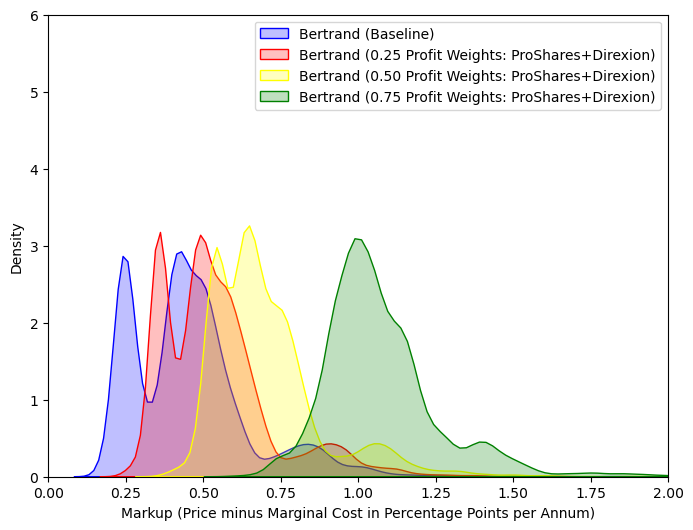

In [33]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=testing_results.markups[1].ravel(), label='Bertrand (Baseline)', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[2].ravel(), label='Bertrand (0.25 Profit Weights: ProShares+Direxion)', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[3].ravel(), label='Bertrand (0.50 Profit Weights: ProShares+Direxion)', color='yellow', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[8].ravel(), label='Bertrand (0.75 Profit Weights: ProShares+Direxion)', color='green', fill=True, alpha=0.25)

plt.xlim(0, 2)
plt.ylim(0, 6)
plt.xlabel('Markup (Price minus Marginal Cost in Percentage Points per Annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Bertrand and Partial Collusion.pdf", format="pdf", bbox_inches="tight")
plt.show()

#plt.savefig("./Bertrand and Partial Collusion Combos.pdf", format="pdf", bbox_inches="tight")
#plt.show()

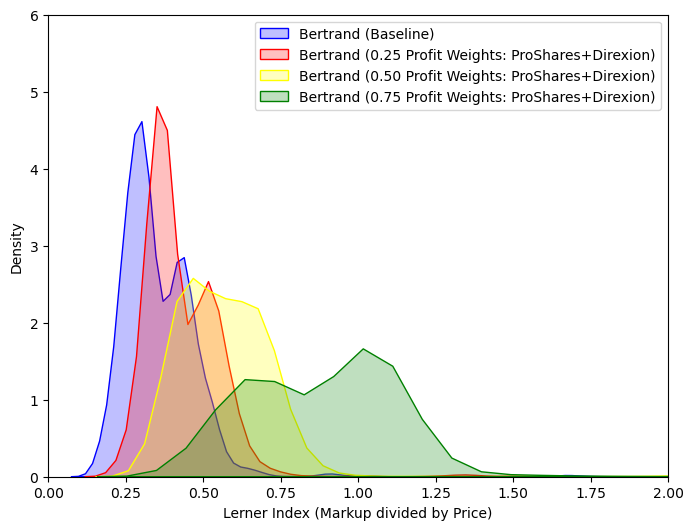

In [34]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_lerner_bt'], label='Bertrand (Baseline)', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_prosh_direx_025'], label='Bertrand (0.25 Profit Weights: ProShares+Direxion)', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_prosh_direx_050'], label='Bertrand (0.50 Profit Weights: ProShares+Direxion)', color='yellow', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_prosh_direx_075'], label='Bertrand (0.75 Profit Weights: ProShares+Direxion)', color='green', fill=True, alpha=0.25)

plt.xlim(0, 2)
plt.ylim(0, 6)
plt.xlabel('Lerner Index (Markup divided by Price)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Lerner Bertrand and Partial Collusion.pdf", format="pdf", bbox_inches="tight")
plt.show()

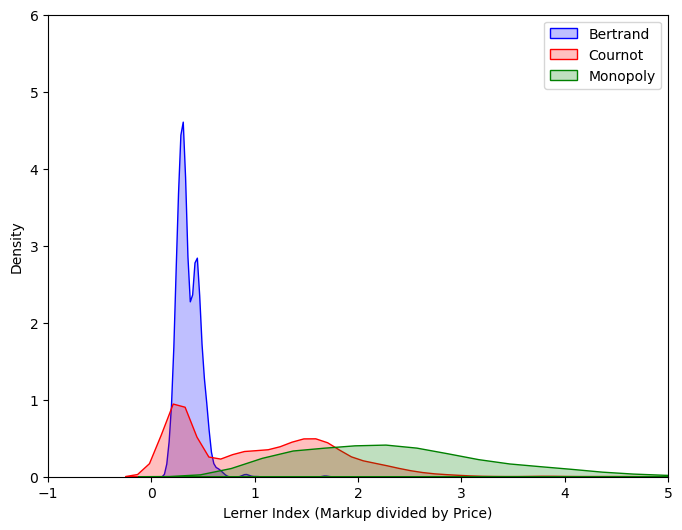

In [35]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_lerner_bt'], label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_cournot'], label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_monopoly'], label='Monopoly', color='green', fill=True, alpha=0.25)

plt.xlim(-1, 5)
plt.ylim(0, 6)
plt.xlabel('Lerner Index (Markup divided by Price)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Lerner Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

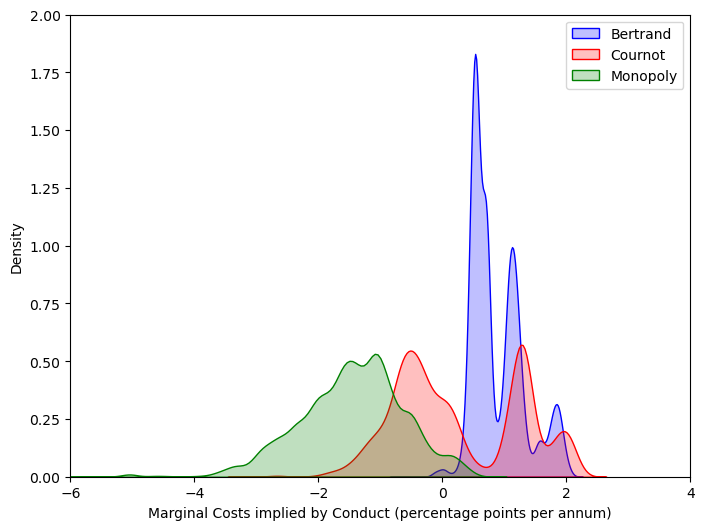

In [36]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_mc_bt'], label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_mc_cournot'], label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_mc_monopoly'], label='Monopoly', color='green', fill=True, alpha=0.25)

plt.xlim(-6, 4)
plt.ylim(0, 2)
plt.xlabel('Marginal Costs implied by Conduct (percentage points per annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./MC Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

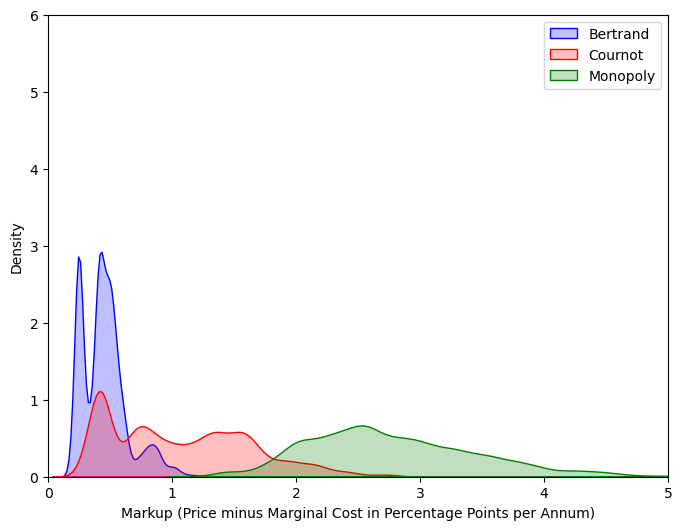

In [37]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=testing_results.markups[1].ravel(), label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[9].ravel(), label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[10].ravel(), label='Monopoly', color='green', fill=True, alpha=0.25)

plt.xlim(0, 5)
plt.ylim(0, 6)
plt.xlabel('Markup (Price minus Marginal Cost in Percentage Points per Annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [38]:
# Save implied marginal costs
product_data.to_csv("lev_product_data_w_costs_Mar2025_broad_special.csv", index=False)
# product_data.to_csv("lev_product_data_w_costs_Mar2025_BLPRC1.csv", index=False)

In [39]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.25 if {f, g} == {"ProShares", "Direxion"}
        else 0.25 if {f, g} == {"ProFunds", "Direxion"}
       else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.5 if {f, g} == {"ProShares", "Direxion"}
        else 0.5 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.55 if {f, g} == {"ProShares", "Direxion"}
        else 0.55 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.6 if {f, g} == {"ProShares", "Direxion"}
        else 0.6 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.65 if {f, g} == {"ProShares", "Direxion"}
        else 0.65 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.7 if {f, g} == {"ProShares", "Direxion"}
        else 0.7 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.75 if {f, g} == {"ProShares", "Direxion"}
        else 0.75 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.039)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

Computing Markups ... 
Total Time is ... 15.88541316986084




Testing Results - Instruments z0:
  TRV:                                     |   F-stats:                                            |    MCS:                
--------  ---  -----  -----  -----  -----  |  ----------  ---  -------  -------  -------  -------  |  --------  ------------
 models    0     1      2      3      4    |    models     0      1        2        3        4     |   models   MCS p-values
--------  ---  -----  -----  -----  -----  |  ----------  ---  -------  -------  -------  -------  |  --------  ------------
   0      nan  2.803  3.041  3.165  3.202  |      0       nan   18.1     19.7     21.9     24.3    |     0         0.004    
                                           |                   *** ^^^  *** ^^^  *** ^^^  *** ^^^  |                        
   1      nan   nan   2.614  2.795  2.865  |      1       nan    nan      7.3      8.8     10.8    |     1         0.004    
                                           |                            *** ^^^  *** ^^^ 

In [40]:
# Robustness to alternative IVs

# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.040)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret + BLP_IV_rival_funds2', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2:Conduct_IV_csent_index_resid + Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid (Strongest), Conduct_IV_csent_income2_resid, Conduct_IV_csent_income3_resid (Weakest)
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1, Conduct_IV_csent_age2, Conduct_IV_csent_age3 (All about the same)
# This works: BLP_IV_rival_funds2*rotator
# rotator by itself is similar directions but insignificant
# Conduct_IV_csent_index_resid by itself is insignificant
# BLP_IV_rival_funds2 by itself is similar directions but insignificant
# BLP_IV_rival_funds3 by itself is perfect competition/ most interactions with BLP_IV_rival_funds3 have PC == PW

# Results are stronger if only the interaction is in the IV and the standalone terms are put into the cost formulation


### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

Computing Markups ... 
Total Time is ... 16.537225246429443




Testing Results - Instruments z0:
  TRV:                                     |   F-stats:                                            |    MCS:                
--------  ---  -----  -----  -----  -----  |  ----------  ---  -------  -------  -------  -------  |  --------  ------------
 models    0     1      2      3      4    |    models     0      1        2        3        4     |   models   MCS p-values
--------  ---  -----  -----  -----  -----  |  ----------  ---  -------  -------  -------  -------  |  --------  ------------
   0      nan  4.184  4.625  4.921  5.062  |      0       nan   23.8     25.3     28.1     32.0    |     0          0.0     
                                           |                   *** ^^^  *** ^^^  *** ^^^  *** ^^^  |                        
   1      nan   nan   3.42   3.82   4.063  |      1       nan    nan      8.0     11.1     14.6    |     1          0.0     
                                           |                            *** ^^   *** ^^^ 

In [41]:
testing_results.markups[0][product_data['month_t'] > (2020+9/12)] = 0
testing_results.markups[1][product_data['month_t'] > (2020+9/12)] = 0
testing_results.markups[2][product_data['month_t'] > (2020+9/12)] = 0
testing_results.markups[3][product_data['month_t'] > (2020+9/12)] = 0
testing_results.markups[4][product_data['month_t'] > (2020+9/12)] = 0

product_data_econ_scale_post=copy.deepcopy(product_data_econ_scale)

product_data_econ_scale_post['perfect_competition_post'] = testing_results.markups[0]
product_data_econ_scale_post['bertrand_post'] = testing_results.markups[1]
product_data_econ_scale_post['bt_prosh_direx_025'] = testing_results.markups[2]
product_data_econ_scale_post['bt_prosh_direx_050'] = testing_results.markups[3]
product_data_econ_scale_post['bt_prosh_direx_075'] = testing_results.markups[4]

# Now set up problem for conduct testing in sub-samples
testing_problem_post = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')        
        #  List of candidate instruments
#  77  Conduct_IV_abs_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  78  Conduct_IV_abs_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  79  Conduct_IV_abs_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64
#  80  Conduct_IV_pos_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  81  Conduct_IV_pos_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  82  Conduct_IV_pos_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64
#  83  Conduct_IV_neg_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  84  Conduct_IV_neg_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  85  Conduct_IV_neg_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64


    ),
    model_formulations = (
        pyRVtest.ModelFormulation(user_supplied_markups='perfect_competition_post'),
        pyRVtest.ModelFormulation(user_supplied_markups='bertrand_post'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_prosh_direx_025'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_prosh_direx_050'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_prosh_direx_075')
    ),
    product_data = product_data_econ_scale_post,
    demand_results = results_v3
)
testing_problem_post

testing_results_post = testing_problem_post.solve(
    demand_adjustment=False,    
    clustering_adjustment=False
)
testing_results_post

Computing Markups ... 
Total Time is ... 2.4616482257843018




Testing Results - Instruments z0:
  TRV:                                         |   F-stats:                                            |    MCS:                
--------  ---  ------  ------  ------  ------  |  ----------  ---  -------  -------  -------  -------  |  --------  ------------
 models    0     1       2       3       4     |    models     0      1        2        3        4     |   models   MCS p-values
--------  ---  ------  ------  ------  ------  |  ----------  ---  -------  -------  -------  -------  |  --------  ------------
   0      nan  -2.969  -2.997  -3.17   -3.396  |      0       nan   25.5     28.0     29.9     31.0    |     0          1.0     
                                               |                   *** ^^^  *** ^^^  *** ^^^  *** ^^^  |                        
   1      nan   nan    1.733   0.607   -0.464  |      1       nan    nan     18.3     22.3     25.6    |     1         0.003    
                                               |             

In [42]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.25 if {f, g} == {"ProShares", "Direxion"}
        else 0.25 if {f, g} == {"ProFunds", "Direxion"}
       else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.5 if {f, g} == {"ProShares", "Direxion"}
        else 0.5 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.55 if {f, g} == {"ProShares", "Direxion"}
        else 0.55 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.6 if {f, g} == {"ProShares", "Direxion"}
        else 0.6 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.65 if {f, g} == {"ProShares", "Direxion"}
        else 0.65 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.7 if {f, g} == {"ProShares", "Direxion"}
        else 0.7 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.75 if {f, g} == {"ProShares", "Direxion"}
        else 0.75 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.040)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

Computing Markups ... 
Total Time is ... 15.089151620864868




Testing Results - Instruments z0:
  TRV:                                     |   F-stats:                                            |    MCS:                
--------  ---  -----  -----  -----  -----  |  ----------  ---  -------  -------  -------  -------  |  --------  ------------
 models    0     1      2      3      4    |    models     0      1        2        3        4     |   models   MCS p-values
--------  ---  -----  -----  -----  -----  |  ----------  ---  -------  -------  -------  -------  |  --------  ------------
   0      nan  2.803  3.056  3.191  3.234  |      0       nan   18.2     19.8     22.0     24.4    |     0         0.004    
                                           |                   *** ^^^  *** ^^^  *** ^^^  *** ^^^  |                        
   1      nan   nan   2.65   2.836  2.91   |      1       nan    nan      7.3      8.8     10.8    |     1         0.004    
                                           |                            *** ^^^  *** ^^^ 

In [43]:
testing_results.markups[0][product_data['month_t'] <= (2020+9/12)] = 0
testing_results.markups[1][product_data['month_t'] <= (2020+9/12)] = 0
testing_results.markups[2][product_data['month_t'] <= (2020+9/12)] = 0
testing_results.markups[3][product_data['month_t'] <= (2020+9/12)] = 0
testing_results.markups[4][product_data['month_t'] <= (2020+9/12)] = 0

product_data_econ_scale_post=copy.deepcopy(product_data_econ_scale)

product_data_econ_scale_post['perfect_competition_post'] = testing_results.markups[0]
product_data_econ_scale_post['bertrand_post'] = testing_results.markups[1]
product_data_econ_scale_post['bt_prosh_direx_025'] = testing_results.markups[2]
product_data_econ_scale_post['bt_prosh_direx_050'] = testing_results.markups[3]
product_data_econ_scale_post['bt_prosh_direx_075'] = testing_results.markups[4]

# Now set up problem for conduct testing in sub-samples
testing_problem_post = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')        
        #  List of candidate instruments
#  77  Conduct_IV_abs_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  78  Conduct_IV_abs_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  79  Conduct_IV_abs_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64
#  80  Conduct_IV_pos_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  81  Conduct_IV_pos_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  82  Conduct_IV_pos_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64
#  83  Conduct_IV_neg_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  84  Conduct_IV_neg_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  85  Conduct_IV_neg_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64


    ),
    model_formulations = (
        pyRVtest.ModelFormulation(user_supplied_markups='perfect_competition_post'),
        pyRVtest.ModelFormulation(user_supplied_markups='bertrand_post'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_prosh_direx_025'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_prosh_direx_050'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_prosh_direx_075')
    ),
    product_data = product_data_econ_scale_post,
    demand_results = results_v3
)
testing_problem_post

testing_results_post = testing_problem_post.solve(
    demand_adjustment=False,    
    clustering_adjustment=False
)
testing_results_post

Computing Markups ... 
Total Time is ... 2.5202252864837646




Testing Results - Instruments z0:
  TRV:                                     |   F-stats:                                            |    MCS:                
--------  ---  -----  -----  -----  -----  |  ----------  ---  -------  -------  -------  -------  |  --------  ------------
 models    0     1      2      3      4    |    models     0      1        2        3        4     |   models   MCS p-values
--------  ---  -----  -----  -----  -----  |  ----------  ---  -------  -------  -------  -------  |  --------  ------------
   0      nan  1.877  2.038  2.229  2.285  |      0       nan   25.5     26.2     27.0     27.7    |     0         0.042    
                                           |                   *** ^^^  *** ^^^  *** ^^^  *** ^^^  |                        
   1      nan   nan   2.48   2.521  2.206  |      1       nan    nan     11.8     19.3     24.6    |     1         0.033    
                                           |                            *** ^^^  *** ^^^ 